# Example notebook

This notebook is a template. It shows every element the site knows how to render, and how to write each one. Copy it, rename the file, and replace the content.

## 1. Title, introduction and sections

- The first line of the first cell is the page title: `# Example notebook`.
- The paragraph under it is the introduction. Its first sentences are used as the summary in the notebook list when no summary is set in the metadata.
- Every `## Heading` starts a new section and adds an entry to the **Contents** sidebar. Number them (`## 1. ...`, `## 2. ...`) to keep the order visible.
- `### Sub-heading` is allowed inside a section and does not appear in the sidebar.

## 2. Text and formulas

Text is Markdown: **bold**, *italic*, `inline code`, lists and tables.

Inline math goes between single dollars, for example $\mu$ and $\sigma^2$. A displayed formula goes between double dollars, on its own paragraph:

$$\bar{X}_n = \frac{1}{n} \sum_{i=1}^{n} X_i, \qquad \operatorname{Var}(\bar{X}_n) = \frac{\sigma^2}{n}$$

| Element | Rendered |
|---|---|
| Greek letters, indices | $\alpha_t$, $\beta^{(k)}$ |
| Fractions and roots | $\frac{a}{b}$, $\sqrt{x}$ |
| Expectation | $\mathbb{E}[X]$ |

## 3. Setup cell

Keep imports and plot styling in one cell at the top. The colours below match the site's dark theme.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#0E1117", "axes.facecolor": "#0E1117", "savefig.facecolor": "#0E1117",
    "axes.edgecolor": "#3A3F48", "axes.labelcolor": "#C9CDD6", "text.color": "#ECEDF1",
    "xtick.color": "#A9AFBC", "ytick.color": "#A9AFBC", "grid.color": "#2A2E36",
    "axes.grid": True, "grid.alpha": 0.6, "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=["#8FAAFF", "#FFB27A", "#5DCAA5", "#F4A3C0"]),
})
pd.set_option("display.precision", 4)
rng = np.random.default_rng(7)  # fixed seed: the outputs are reproducible

## 4. Code with printed output

Anything a cell prints is shown under the code. Here we check the formula of section 2 by simulation: the variance of the mean of $n$ draws should be $\sigma^2 / n$.

In [2]:
sigma, n, trials = 2.0, 50, 20_000
means = rng.normal(0.0, sigma, size=(trials, n)).mean(axis=1)
print(f"empirical variance of the mean: {means.var():.4f}")
print(f"theory sigma^2 / n:             {sigma**2 / n:.4f}")

empirical variance of the mean: 0.0809
theory sigma^2 / n:             0.0800


## 5. Tables

A pandas DataFrame left as the last expression of a cell is rendered as a table.

In [3]:
sizes = [10, 50, 250, 1000]
rows = []
for size in sizes:
    m = rng.normal(0.0, sigma, size=(5_000, size)).mean(axis=1)
    rows.append({"n": size, "empirical": m.var(), "theory": sigma**2 / size})
pd.DataFrame(rows).set_index("n")

,empirical,theory
n,,
10,0.4134,0.400
50,0.0808,0.080
250,0.0161,0.016
1000,0.0040,0.004


## 6. Figures

A matplotlib figure is saved as an image and shown under the cell. Label the axes and add a legend: the figure is read without the code when the reader hides it.

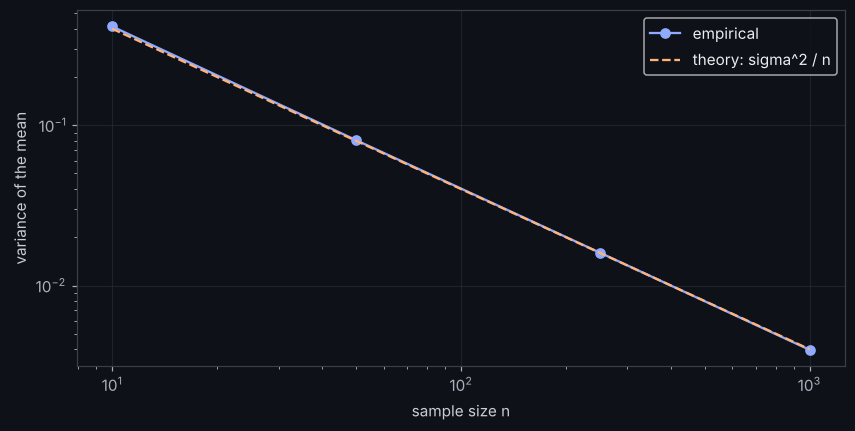

In [4]:
table = pd.DataFrame(rows)
fig, ax = plt.subplots()
ax.loglog(table["n"], table["empirical"], marker="o", label="empirical")
ax.loglog(table["n"], table["theory"], linestyle="--", label="theory: sigma^2 / n")
ax.set_xlabel("sample size n"); ax.set_ylabel("variance of the mean"); ax.legend()
plt.show()

## 7. Before publishing

**Run all cells, then save.** The site shows the outputs stored in the file and never runs code.

Set the domain and the summary in the notebook metadata (Jupyter: *Edit → Notebook metadata*):

```json
"quantcodex": { "domain": "example", "summary": "One line shown in the notebook list" }
```

Save the file as `notebooks/<name>.ipynb`. The file name becomes the page address (`/notebooks/<name>/`) and the domain feeds the filter of the notebook list.

Push. The site rebuilds by itself.